In [1]:
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt

raw_data = sio.loadmat("../Data/python_training_data.mat", squeeze_me=True, struct_as_record=False)

STATE_NAMES = [
    "motT (K)", "invT (K)", "dcdcT (K)", "batSoc (-)", "batT (K)",
    "compPin (Pa)", "compPout (Pa)", "cabIntT (K)", "cabAirT (K)"
]
INPUT_NAMES = [
    "compNrpm (rpm)", "cabAirMfIn (kg/s)", "motPumpNrpm (rpm)",
    "batPumpNrpm (rpm)", "heaterPwr (W)", "radFanrpm (rpm)"
]

def parse_scenario(mat_struct, tamb_c):
    est_dict = {f: np.asarray(getattr(mat_struct.est, f), dtype=np.float64) 
                for f in mat_struct.est._fieldnames}
    ctrl_dict = {f: np.asarray(getattr(mat_struct.ctrl, f), dtype=np.float64) 
                 for f in mat_struct.ctrl._fieldnames}
    return {
        "Tamb_C": tamb_c,
        "t": np.asarray(mat_struct.t, dtype=np.float64),
        "X": np.asarray(mat_struct.X, dtype=np.float64),
        "U": np.asarray(mat_struct.U, dtype=np.float64),
        "est": est_dict,
        "ctrl": ctrl_dict,
    }

scenarios = {
    -5:  parse_scenario(raw_data["T5"], -5.0),
    -7:  parse_scenario(raw_data["T7"], -7.0),
    -10: parse_scenario(raw_data["T10"], -10.0),
}

for tamb, sc in scenarios.items():
    print(f"=== Scenario Tamb = {tamb}°C ===")
    print(f"  X shape: {sc['X'].shape} | U shape: {sc['U'].shape}")
    print(f"  Initial states X[0]: {np.round(sc['X'][0], 2)}")
    print(f"  Final states   X[-1]: {np.round(sc['X'][-1], 2)}\n")

=== Scenario Tamb = -5°C ===
  X shape: (3601, 9) | U shape: (3601, 6)
  Initial states X[0]: [2.6815e+02 2.6815e+02 2.6815e+02 1.0000e+00 2.6815e+02 2.5000e+05
 2.5000e+05 2.6815e+02 2.6815e+02]
  Final states   X[-1]: [3.07890000e+02 3.07850000e+02 3.06970000e+02 8.70000000e-01
 3.07960000e+02 2.81317200e+05 2.81778687e+06 2.80260000e+02
 2.94150000e+02]

=== Scenario Tamb = -7°C ===
  X shape: (3601, 9) | U shape: (3601, 6)
  Initial states X[0]: [2.6615e+02 2.6615e+02 2.6615e+02 1.0000e+00 2.6615e+02 2.2000e+05
 2.2000e+05 2.6615e+02 2.6615e+02]
  Final states   X[-1]: [3.06340000e+02 3.06290000e+02 3.05390000e+02 8.70000000e-01
 3.06430000e+02 2.67711470e+05 3.04974984e+06 2.79190000e+02
 2.94150000e+02]

=== Scenario Tamb = -10°C ===
  X shape: (3601, 9) | U shape: (3601, 6)
  Initial states X[0]: [2.6315e+02 2.6315e+02 2.6315e+02 1.0000e+00 2.6315e+02 2.0000e+05
 2.0000e+05 2.6315e+02 2.6315e+02]
  Final states   X[-1]: [3.04670000e+02 3.04620000e+02 3.03690000e+02 8.70000000e-0

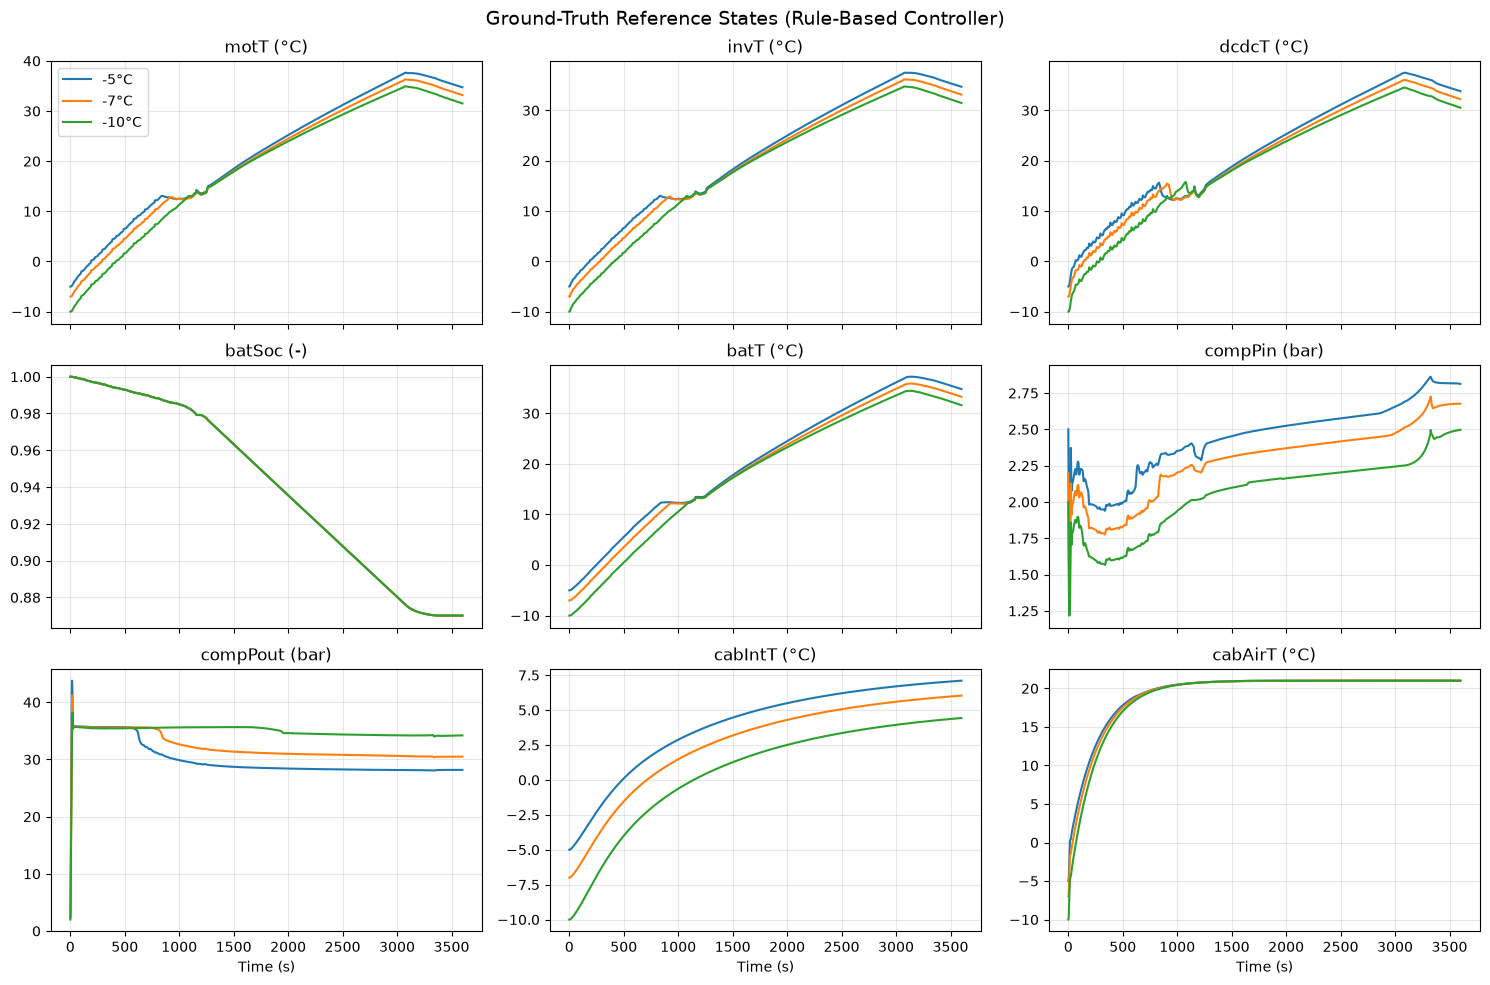

In [2]:
# Cell 2: Plot Ground-Truth States and Control Inputs across -5°C, -7°C, -10°C
fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
axes = axes.flatten()

for idx, name in enumerate(STATE_NAMES):
    ax = axes[idx]
    for tamb, sc in scenarios.items():
        y = sc["X"][:, idx].copy()
        # Convert Kelvin to Celsius or Pa to bar for clean plotting
        if "(K)" in name:
            y = y - 273.15
            ylabel = name.replace("(K)", "(°C)")
        elif "(Pa)" in name:
            y = y / 1e5
            ylabel = name.replace("(Pa)", "(bar)")
        else:
            ylabel = name
        ax.plot(sc["t"], y, label=f"{tamb}°C")
    ax.set_title(ylabel)
    ax.grid(True, alpha=0.3)
    if idx == 0:
        ax.legend()
    if idx >= 6:
        ax.set_xlabel("Time (s)")

plt.suptitle("Ground-Truth Reference States (Rule-Based Controller)", fontsize=14)
plt.tight_layout()
plt.show()